# Notebook 6.4 — Mode-space L2 eigendecomposition mechanism (patch level)

*No DP guarantee — every number here is correctness, efficiency or utility on a proof-of-concept harness.
Patch-level **privacy is not tested here**; the privacy tests run on the whole release in NB7.*

This notebook tests one mechanism in three respects: **correctness** (does it build the noise it claims to?),
**efficiency** (what does acceptance/rejection cost, and how does it scale with patch size?), and **utility**
(how faithfully does the released field preserve the signal?).

**The mechanism in one paragraph.** For a patch, take the leave-one-out (LOO) perturbations `D` (one row per
subject, `N × p`). Its covariance `Cov(LOO)` has `r = min(p, N−1)` eigenmodes `V_m` with eigenvalues `λ_m`.
The mechanism draws correlated noise as one independent coefficient per mode,
`z = Σ_m a_m V_m` with `a_m = scale · √λ_m · ξ_m`, `ξ_m ~ 𝒩(0,1)`. It selects the single most influential
subject in whole-patch L2 norm, `i* = argmax_i ‖D_i‖₂`, and places a **mode-space rejection bar**
`b_m = |D_{i*} · V_m|`; a draw is accepted when its coefficients clear that bar in the policed modes, else a
tail-resampling fallback is used. Everything lives in the `r`-dimensional mode space; the only `p`-dimensional
object ever formed is the one assembled noise field for the accepted draw.

**Two knobs recur throughout — fix their meaning now:**

| knob | what it controls | range |
|------|------------------|-------|
| **`k_noise`** | how many modes receive noise (`a_m=0` for `m>k_noise`) — the **rank of the noise** | `1 … r`; default `r` (full-rank) |
| **`k_check`** | how many modes the accept rule polices (`\|a_m\| ≥ b_m` for `m ≤ k_check`) — the **rejection depth** | `0 … k_noise`; `0` = no rejection |

Full-rank noise (`k_noise = r`) is what privacy requires; `k_check` is the acceptance lever, studied in §3.

## §0 — Setup, integrity, substrate

BLAS is pinned to one thread before NumPy is imported; the three unmodified support modules are hash-checked
(the run aborts on any mismatch); seeds are fixed. The substrate is real **OASIS** gray-matter patches when
`USE_OASIS = True`, else a portable synthetic phantom. Small patches are sliced as fully-in-brain blocks; the
**big** patch (`BIG_SIZE`, the OASIS-scale size carried over from the patch-sizing notebook) is taken as a
brain-centred block on OASIS and synthesised on the phantom (which is too small to contain it).

In [1]:
import os
for _env in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
             "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[_env] = "1"                       # pin BLAS BEFORE importing NumPy
import hashlib, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import svd
from scipy import ndimage
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- integrity: the three support modules must be byte-identical ----
SUPPORT_SHA = {
    "privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
    "cov_diagnostics.py": "d91b33cf7e532ee676d16532830ea65f263a5c0277cc4bd34d768908d2601013",
    "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018",
}
for module_file, expected in SUPPORT_SHA.items():
    actual = hashlib.sha256(open(module_file, "rb").read()).hexdigest()
    assert actual == expected, f"MODULE MODIFIED: {module_file}"
print("support modules verified:", ", ".join(SUPPORT_SHA))

import privacy_harness as ph
import cov_diagnostics as cd
import l2_sensitivity as l2s
import mode_eigen_mech as me
import tiling as tl

# ---- plot conventions ----
STAT_COLOR = {"mean": "#4c72b0", "median": "#dd8452", "variance": "#55a868"}   # by statistic
MECH_COLOR = {"mode-eigen": "#c44e52", "voxel-L2": "#8172b3", "voxel-max": "#937860"}  # by mechanism
PIPELINES  = {"mean": ph.pipeline_mean, "median": ph.pipeline_median, "variance": ph.pipeline_variance}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 10, "axes.labelsize": 9})

# ---- configuration ----
SEED            = 0
N_SUBJECTS      = 40                       # subjects per patch -> mode-rank ceiling r = N-1 = 39
EPSILON         = 1.0
SMALL_SIZES     = [(4, 4, 4), (6, 6, 6), (8, 8, 8)]   # where the 3-way comparison is affordable
BIG_SIZE        = (35, 35, 35)             # OASIS-scale patch from the patch-sizing notebook (p ~ 42.9k)
SCALE_GRID      = [1.0, 2.0, 3.0, 4.0]              # shared noise-scale sweep axis
KCHECK_GRID     = [0, 1, 2, 4, 8, 16, 24, 32, 39]       # rejection-depth sweep axis for the fallback map
USE_OASIS       = True

# ---- fixed operating point (your chosen sweet spot) — used by every plot that does NOT sweep that knob ----
FIXED_SCALE     = 3.0                      # per-mode noise scale for single-scale plots (§2, §3b/c, §3d, §4b)
FIXED_KCHECK    = 39                       # rejection depth for the single-config budget curve (§3b/c)
FIXED_MAXDRAWS  = 3000                     # draw budget for plots that do not sweep it (§3a, §3d, §4a/b, big-patch)
print(f"substrate: {'OASIS' if USE_OASIS else 'synthetic phantom'} | N_subjects={N_SUBJECTS} | "
      f"big size={BIG_SIZE} | operating point: scale={FIXED_SCALE}, k_check={FIXED_KCHECK}, "
      f"max_draws={FIXED_MAXDRAWS}")

support modules verified: privacy_harness.py, cov_diagnostics.py, inference_eval.py
substrate: OASIS | N_subjects=40 | big size=(35, 35, 35) | operating point: scale=3.0, k_check=39, max_draws=3000


In [2]:
# ---- substrate + patch accessors -------------------------------------------------
# Terminology used throughout:
#   * a PATCH is one spatial block (one Cov(LOO), one set of modes).
#   * a DRAW  is one sample of the mechanism (one candidate->accept/fallback->one noise field).
#   * a TRIAL is one repetition over a fresh patch (varying SEED) used for error bars.
if USE_OASIS:
    _sub = tl.load_oasis_volumes(n=max(100, N_SUBJECTS))
else:
    _sub = tl.make_phantom(shape=(40, 40, 36), M=80, N=N_SUBJECTS,   # large enough for a fully-in-brain 16^3
                           corr_lens=(2.0, 4.0, 6.0), seed=SEED)
VOLUMES, BRAIN_MASK = _sub["volumes"], _sub["mask"]
print(f"volumes {VOLUMES.shape}, in-brain voxels = {int(BRAIN_MASK.sum()):,}")

def effective_rank_95(eigenvalues):
    '''Smallest k whose top-k modes hold >=95% of the total eigen-energy (the '95% effective rank').'''
    cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
    return int(np.searchsorted(cumulative, 0.95) + 1)

def small_patch_artifacts(patch_shape, pipeline=ph.pipeline_mean, patch_seed=SEED, draw_seed=0):
    '''One fully-in-brain small patch -> (clean statistic y, LOO perturbations D, per-voxel bar S).'''
    source = ph.ArrayBlockSource(VOLUMES, BRAIN_MASK, block_shape=patch_shape,
                                 N=N_SUBJECTS, seed=patch_seed)
    subjects = source.sample(N_SUBJECTS, np.random.default_rng(draw_seed))
    return ph.loo_artifacts(subjects, pipeline)

def _brain_centred_block(patch_shape, jitter=0):
    '''A BIG block centred on the brain mask's centroid (clipped to the volume), + a small reproducible
    jitter so repeated trials see different big patches. Used for OASIS, where a fully-in-brain 35^3 cube
    may not exist; out-of-brain voxels are constant across subjects and drop out of the LOO perturbations.'''
    centroid = np.argwhere(BRAIN_MASK).mean(0).astype(int)
    shape = np.array(patch_shape)
    rng = np.random.default_rng(1000 + jitter)
    offset = rng.integers(-3, 4, size=3) if jitter else np.zeros(3, int)
    start = np.clip(centroid - shape // 2 + offset, 0, np.array(BRAIN_MASK.shape) - shape)
    sl = tuple(slice(s, s + n) for s, n in zip(start, shape))
    block = VOLUMES[(slice(None),) + sl]                      # (M pooled subjects, *patch_shape)
    subject_idx = rng.choice(block.shape[0], size=min(N_SUBJECTS, block.shape[0]), replace=False)
    return block[subject_idx]                                # subsample to N_SUBJECTS, like the small path

def _synth_big_block(patch_shape, trial_seed=0):
    '''A spatially-correlated synthetic big block (phantom path, which cannot contain a 35^3 in-brain cube).'''
    rng = np.random.default_rng(2000 + trial_seed)
    template = ndimage.gaussian_filter(rng.standard_normal(patch_shape), 5.0)
    subjects = np.stack([template + ndimage.gaussian_filter(rng.standard_normal(patch_shape), 4.0)
                         for _ in range(N_SUBJECTS)])
    return subjects

def big_patch_artifacts(pipeline=ph.pipeline_mean, trial_seed=0):
    '''One BIG_SIZE patch -> (y, D, S). Real brain-centred block on OASIS; synthetic on the phantom.'''
    subjects = (_brain_centred_block(BIG_SIZE, jitter=trial_seed) if USE_OASIS
                else _synth_big_block(BIG_SIZE, trial_seed))
    return ph.loo_artifacts(subjects.reshape(N_SUBJECTS, -1), pipeline)   # flatten to (N, p) like small patches

_y, _D, _S = small_patch_artifacts((4, 4, 4))
print(f"sample small patch: p={_y.size}, modes r={me.patch_modes(_D)[1].size}")
_yb, _Db, _Sb = big_patch_artifacts()
print(f"big patch: p={_yb.size:,}, modes r={me.patch_modes(_Db)[1].size}")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
volumes (100, 91, 109, 91), in-brain voxels = 875,291
sample small patch: p=64, modes r=39
big patch: p=42,875, modes r=39


## §1 — The noise covariance spectrum and its 95% effective rank

**Question.** How is the noise energy distributed across modes, and how many modes hold most of it? This fixes
the `r` and the *data-derived* `k` (the 95% effective rank) that later experiments refer to.

**Plot.** One panel, two y-axes, shared x = mode index `m` (ordered by decreasing variance). Left axis (log):
the eigenvalue `λ_m` = variance along mode `m`. Right axis (linear): cumulative energy `Σ_{≤m} λ / Σ λ`. The
dotted horizontal line marks 95% energy; the vertical line marks the **95% effective rank** `k₉₅` where the
cumulative curve crosses it.

**How to read it (any dataset).** A steep `λ` decay with an early `k₉₅` ≪ `r` means the energy is concentrated
in a few smooth modes; a shallow decay with `k₉₅` near `r` means energy is spread across many modes. Either
way the mechanism noises **all** `r` modes by default — `k₉₅` is a description of the energy, **not** a licence
to truncate the noise (a low-energy tail mode still carries signal). Compare the small and big patch: the mode
*count* is capped at `r = N−1` regardless of `p`, but the spectrum shape can differ.

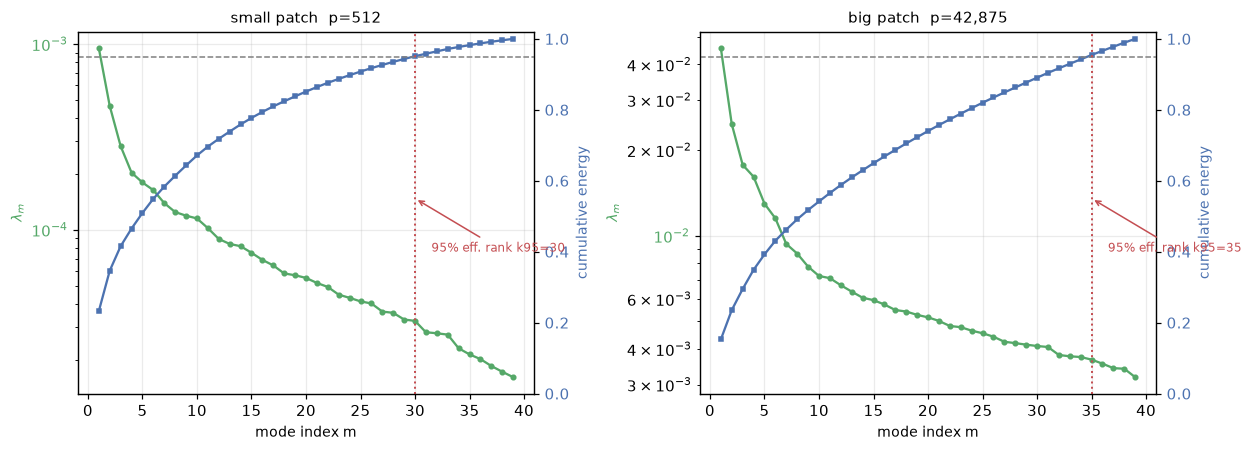

[read-off] 95% effective rank: small patch k95=30 of r=39; big patch k95=35 of r=39.
           The noise is still drawn over ALL r modes by default; k95 describes energy, not a
           privacy budget. This k95 (big patch) is carried into §3 as the data-derived k marker.


In [3]:
# Spectrum + cumulative energy for a small and the big patch; mark the 95% effective rank of each.
def spectrum_panel(ax, eigenvalues, title):
    modes = np.arange(1, eigenvalues.size + 1)
    cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
    k95 = effective_rank_95(eigenvalues)
    ax.semilogy(modes, eigenvalues, "o-", ms=3, color="#55a868", label=r"$\lambda_m$ (variance)")
    ax.set_xlabel("mode index m"); ax.set_ylabel(r"$\lambda_m$", color="#55a868")
    ax.tick_params(axis="y", labelcolor="#55a868")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(modes, cumulative, "s-", ms=3, color="#4c72b0", label="cumulative energy")
    ax2.set_ylabel("cumulative energy", color="#4c72b0"); ax2.tick_params(axis="y", labelcolor="#4c72b0")
    ax2.set_ylim(0, 1.02); ax2.axhline(0.95, ls="--", color="gray", lw=1)
    ax2.axvline(k95, ls=":", color="#c44e52", lw=1.3)
    ax2.annotate(f"95% eff. rank k95={k95}", (k95, 0.55), fontsize=8, color="#c44e52",
                 xytext=(k95 + 1.5, 0.4), arrowprops=dict(arrowstyle="->", color="#c44e52"))
    ax.set_title(title)
    return k95

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
_, D_small, _ = small_patch_artifacts((8, 8, 8))
lam_small = me.patch_modes(D_small)[1]
k95_small = spectrum_panel(axes[0], lam_small, f"small patch  p={np.prod((8,8,8))}")
_, D_big, _ = big_patch_artifacts()
lam_big = me.patch_modes(D_big)[1]
k95_big = spectrum_panel(axes[1], lam_big, f"big patch  p={np.prod(BIG_SIZE):,}")
fig.tight_layout(); plt.show()
print(f"[read-off] 95% effective rank: small patch k95={k95_small} of r={lam_small.size}; "
      f"big patch k95={k95_big} of r={lam_big.size}.\n"
      f"           The noise is still drawn over ALL r modes by default; k95 describes energy, not a\n"
      f"           privacy budget. This k95 (big patch) is carried into §3 as the data-derived k marker.")

## §2 — Correctness

Two checks that the mechanism builds the noise it claims to.

### §2a — Covariance identity (the construction is exact)

**Question.** With rejection switched off (`k_check = 0`), the draw is a pure correlated Gaussian. Does its
empirical covariance equal the intended `scale² · Cov(LOO)`? If yes, the assembly `z = Σ_m a_m V_m` is correct.

**Plot.** Scatter of every matrix entry: x = entry of `scale² · Cov(LOO)`, y = the same entry of the empirical
covariance over many draws. The dashed line is `y = x`. **Read:** points on the line (entrywise correlation ≈ 1,
relative Frobenius error ≈ 0) confirm the construction. This is a small-patch check on purpose — it is
size-independent, and forming `p × p` at the big patch would need ~15 GB.

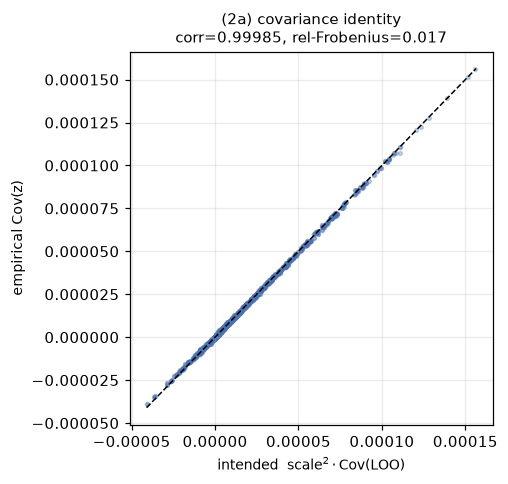

[read-off] over 20,000 natural draws of one patch: entrywise correlation 0.99985, relative Frobenius error 0.017.
           The assembly z = sum_m a_m V_m reproduces the intended covariance -> construction is correct.


In [4]:
# (2a) natural draws (k_check=0) reproduce scale^2 * Cov(LOO). Small patch (size-independent correctness).
y2, D2, S2 = small_patch_artifacts((4, 4, 4))
cov_loo = np.cov(D2, rowvar=False)
target_cov = FIXED_SCALE**2 * cov_loo
draw_rng = np.random.default_rng(1)
natural_model = me.mech_mode_eigen(y2, D2, S2, scale=FIXED_SCALE, k_check=0)
n_draws = 20000
noise_draws = np.array([natural_model.sample(draw_rng) for _ in range(n_draws)])   # (n_draws, p)
empirical_cov = np.cov(noise_draws, rowvar=False)
entrywise_corr = np.corrcoef(empirical_cov.ravel(), target_cov.ravel())[0, 1]
rel_frobenius = np.linalg.norm(empirical_cov - target_cov) / np.linalg.norm(target_cov)

fig, ax = plt.subplots(figsize=(4.7, 4.5))
ax.scatter(target_cov.ravel(), empirical_cov.ravel(), s=6, alpha=0.3, color="#4c72b0")
lims = [min(target_cov.min(), empirical_cov.min()), max(target_cov.max(), empirical_cov.max())]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xlabel=r"intended  scale$^2\cdot$Cov(LOO)", ylabel="empirical Cov(z)",
       title=f"(2a) covariance identity\ncorr={entrywise_corr:.5f}, rel-Frobenius={rel_frobenius:.3f}")
fig.tight_layout(); plt.show()
print(f"[read-off] over {n_draws:,} natural draws of one patch: entrywise correlation {entrywise_corr:.5f}, "
      f"relative Frobenius error {rel_frobenius:.3f}.\n           The assembly z = sum_m a_m V_m reproduces "
      f"the intended covariance -> construction is correct.")

Why the economy SVD is exact (not an approximation). The right singular vectors of the centred LOO matrix Ac (N×p) are precisely the eigenvectors of Cov(LOO) = AcᵀAc/(N−1), with eigenvalues λ_m = s_m²/(N−1). For p > N−1 the covariance has only r = N−1 nonzero eigenvalues, so the economy SVD returns the entire informative spectrum; the p−r omitted modes have λ = 0 and would receive zero noise anyway (sd_m = scale·√λ_m). Forming the full p×p covariance would therefore add nothing — and is infeasible at large p (≈14 GB at 35³), besides being less numerically stable than the SVD. The SVD fixes each mode only up to sign, which is irrelevant here: the coefficients are sign-symmetric and the bar uses |·|.

### §2b — The noise is a combination of eigenmodes

**Question.** Is a drawn noise field literally a smooth combination of the covariance eigenmodes? **Plot.**
Mid-axial slices of the **big** patch: one drawn noise field next to the top two eigenmodes `V₁, V₂`, all on a
shared symmetric diverging scale (blue–red, zero = white). **Read:** the noise should look like a blend of the
smooth spatial patterns `V₁, V₂, …`, not like white speckle — this is what "correlated over voxels =
independent over modes" means, now on real-scale modes.

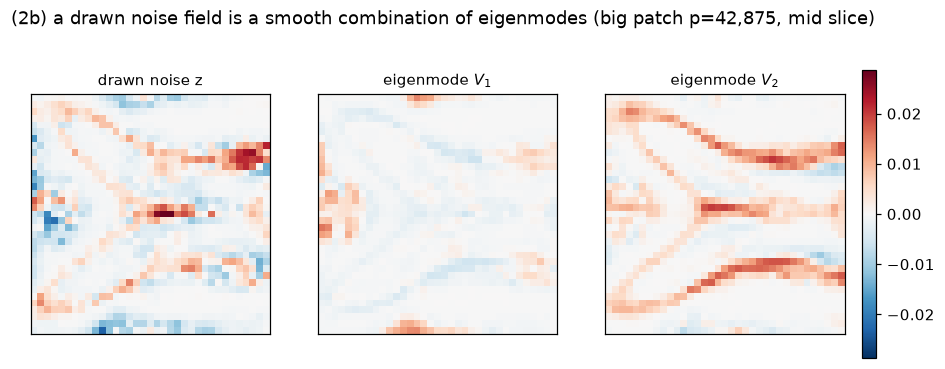

In [5]:
# (2b) one drawn noise field + top two eigenmodes as images (big patch, mid-axial slice).
yb, Db, Sb = big_patch_artifacts()
big_model = me.mech_mode_eigen(yb, Db, Sb, scale=FIXED_SCALE, keep_modes=True)
noise_field = big_model.sample(np.random.default_rng(2)).reshape(BIG_SIZE)
V_big = big_model.modes["V"]
panels = [("drawn noise z", noise_field),
          (r"eigenmode $V_1$", V_big[:, 0].reshape(BIG_SIZE)),
          (r"eigenmode $V_2$", V_big[:, 1].reshape(BIG_SIZE))]
mid = BIG_SIZE[2] // 2
vmax = max(np.abs(img[:, :, mid]).max() for _, img in panels)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (title, img) in zip(axes, panels):
    im = ax.imshow(img[:, :, mid], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
fig.suptitle(f"(2b) a drawn noise field is a smooth combination of eigenmodes "
             f"(big patch p={np.prod(BIG_SIZE):,}, mid slice)", y=1.04)
plt.show()

## §3 — Efficiency: acceptance, budget, timing, and the role of `k_noise`

How often the rejection sampler falls back, what a draw costs, and what happens as more modes are noised and
policed. Recall `k_check` = rejection depth (how many modes must clear the bar), `k_noise` = noise rank.

### §3a — Fallback over the `k_check × scale` plane

**Question.** How does the fallback rate depend on rejection depth `k_check` and noise `scale`, and how does
that change with patch size? **What varies / fixed.** Across cells: `k_check` (rows) and `scale` (columns).
Fixed: `k_noise = r` (full-rank noise), one patch per panel, `n_fallback_samples` draws per cell to estimate
the rate. **`n_fallback_samples`** is the number of independent draws used to *estimate* the fallback
probability in each cell as `n_fallback / n_draws`; larger = less Monte-Carlo noise in the estimate, at linear
cost; it does **not** add patch-to-patch variability (one patch per panel). **Encoding.** Colour = fallback
rate in [0,1] (shared scale). The dashed line marks the **data-derived `k₉₅`** (95% effective rank) on the
`k_check` axis, for reference. **Read:** fallback should rise with `k_check` (more directions to satisfy at
once) and fall with `scale` (more noise clears the bar); `k_check = 0` is the no-rejection row (fallback 0),
`k_check = r` the hardest.

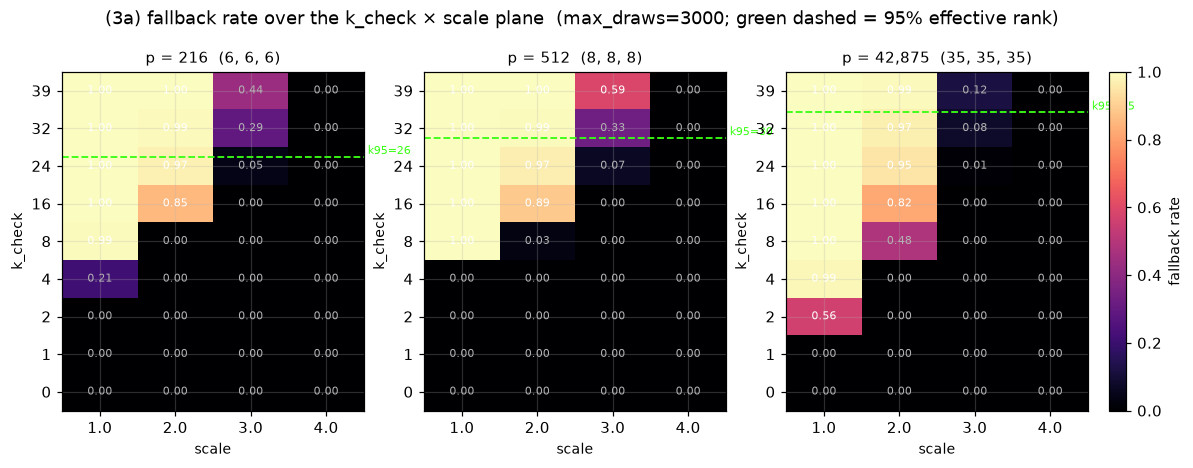

[read-off] every cell uses a draw budget of max_draws=3000. Fallback rises with k_check and
           falls with scale; the 95% effective rank k95 sits inside the policed range, so policing to
           k95 is already in the fallback regime at small scale — motivating scale, not shallow
           k_check, as the acceptance lever.


In [6]:
# (3a) fallback-rate heatmaps over k_check x scale, one panel per size (small x2 + big).
n_fallback_samples = 600           # draws per (k_check, scale) cell used to estimate the fallback rate
MAX_DRAWS_3A = FIXED_MAXDRAWS      # rejection budget behind EVERY cell (fallback = frac needing more)
sizes_3a = [(6, 6, 6), (8, 8, 8), BIG_SIZE]

def fallback_rate_grid(y, D, S, kcheck_values, scale_values, n_draws, max_draws):
    r = me.patch_modes(D)[1].size
    grid = np.full((len(kcheck_values), len(scale_values)), np.nan)
    for i, k_check in enumerate(kcheck_values):
        if k_check > r:
            continue
        for j, scale_value in enumerate(scale_values):
            model = me.mech_mode_eigen(y, D, S, scale=scale_value, k_check=k_check, max_draws=max_draws)
            rng = np.random.default_rng(0)
            for _ in range(n_draws):
                model.sample(rng)
            grid[i, j] = model.fallback_rate
    return grid, r

fig, axes = plt.subplots(1, len(sizes_3a), figsize=(4.2 * len(sizes_3a), 4.0))
for ax, patch_shape in zip(np.atleast_1d(axes), sizes_3a):
    y, D, S = (big_patch_artifacts() if patch_shape == BIG_SIZE
               else small_patch_artifacts(patch_shape))
    grid, r = fallback_rate_grid(y, D, S, KCHECK_GRID, SCALE_GRID, n_fallback_samples, MAX_DRAWS_3A)
    k95 = effective_rank_95(me.patch_modes(D)[1])
    im = ax.imshow(grid, origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax.set_xticks(range(len(SCALE_GRID))); ax.set_xticklabels(SCALE_GRID)
    ax.set_yticks(range(len(KCHECK_GRID))); ax.set_yticklabels(KCHECK_GRID)
    ax.set_xlabel("scale"); ax.set_ylabel("k_check")
    ax.set_title(f"p = {np.prod(patch_shape):,}  {patch_shape}")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            if np.isfinite(grid[i, j]):
                ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="w" if grid[i, j] > 0.5 else "0.7")
    if k95 <= max(KCHECK_GRID):                       # mark the data-derived k on the k_check axis
        y_frac = np.interp(k95, KCHECK_GRID, range(len(KCHECK_GRID)))
        ax.axhline(y_frac, color="#39FF14", ls="--", lw=1.2)
        ax.text(len(SCALE_GRID) - 0.5, y_frac, f" k95={k95}", color="#39FF14", fontsize=7, va="bottom")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="fallback rate")
fig.suptitle(f"(3a) fallback rate over the k_check × scale plane  "
             f"(max_draws={MAX_DRAWS_3A}; green dashed = 95% effective rank)", y=1.02)
plt.show()
print(f"[read-off] every cell uses a draw budget of max_draws={MAX_DRAWS_3A}. Fallback rises with k_check and\n"
      f"           falls with scale; the 95% effective rank k95 sits inside the policed range, so policing to\n"
      f"           k95 is already in the fallback regime at small scale — motivating scale, not shallow\n"
      f"           k_check, as the acceptance lever.")

### §3b/§3c — Draw budget vs fallback and vs time

**Question.** If we cap the rejection sampler at `max_draws = D`, how do the fallback rate and the per-release
time trade off? **Method.** On one interior configuration (partial fallback), record the draws-to-accept once
at a high cap, then derive, for every budget `D`: fallback(D) = fraction of releases needing more than `D`
candidates, and time(D) = `per_draw × mean(min(draws, D))`. `per_draw` is the cost of **one** candidate
draw+bar-check (timed from a large vectorised batch). **One figure, two y-axes**, shared log-x budget `D`: left
(red) = fallback(D) ∈ [0,1], dimensionless; right (brown) = **mean rejection time per released field**, in µs —
per **one patch's** noise release, **excluding** the one-time SVD and the single final assembly. Reference lines
at D = 32, 2000, 1e5. **Read:** more budget buys lower fallback at a linear time cost. **On the crossing:** the
two curves meet somewhere, but that point carries **no intrinsic meaning** — the axes are in different units (a
rate vs µs), so the crossing slides if either axis is rescaled (ms vs µs, % vs fraction). It is a visual
diminishing-returns cue, *not* an optimum; a true optimum would need a cost that weights a fallback event
against a microsecond, which we have not defined here.

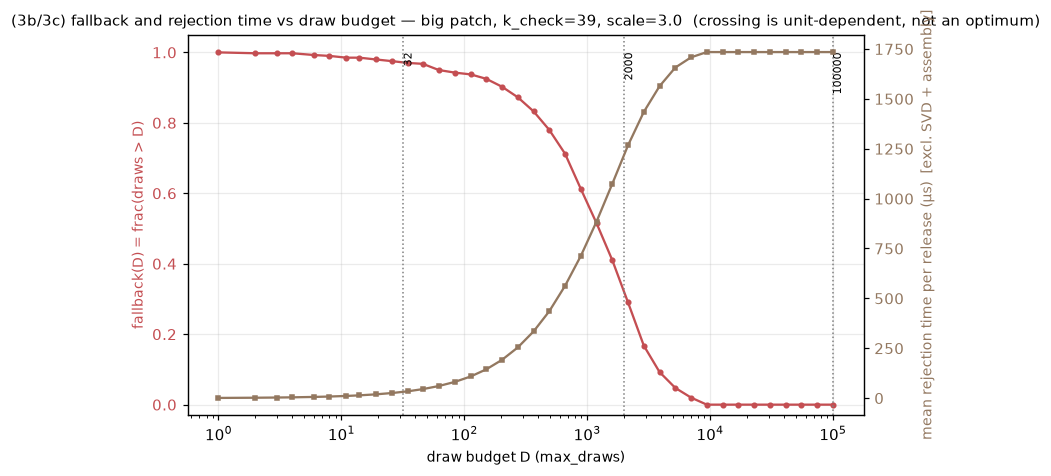

[read-off] big patch, k_check=39, scale=3.0: one candidate draw+check ≈ 1003 ns.
           Budget 32 -> 2000 -> 1e5 moves fallback 0.97 -> 0.32 -> 0.00, at first-linearly-growing time per release.
           The TIME curve PLATEAUS once the budget exceeds the largest draws-to-accept (~9410
           here) and fallback has hit ~0: beyond that point extra budget is never used, so the mean
           saturates at mean(draws_to_accept)*per_draw — the budget has stopped being the binding
           constraint. The curves cross, but the crossing moves with the axis units — read it as
           diminishing returns, not an optimum.


In [7]:
# (3b/3c) budget curve on one interior config of the BIG patch (where fallback is substantial).
yB, DB, SB = big_patch_artifacts()
interior_kcheck, budget_cap = FIXED_KCHECK, 100000      # budget_cap is the high cap we SWEEP max_draws up to
budget_model = me.mech_mode_eigen(yB, DB, SB, scale=FIXED_SCALE, k_check=interior_kcheck,
                                  max_draws=budget_cap, keep_modes=True)
k_noise, k_check, mode_sd, bar = (budget_model.modes[k] for k in ("k_noise", "k_check", "sd", "bar"))

# cost of ONE candidate draw + bar-check, from a big vectorised batch (not the short-circuiting sampler)
batch = 200000
_t0 = time.perf_counter()
_candidates = np.random.default_rng(1).standard_normal((batch, k_noise)) * mode_sd[None, :]
_ = np.all(np.abs(_candidates[:, :k_check]) >= bar[:k_check], axis=1)
seconds_per_candidate = (time.perf_counter() - _t0) / batch

rng = np.random.default_rng(0)
for _ in range(400):                               # record draws-to-accept (budget_cap+1 == fell back)
    budget_model.sample(rng)
draws_to_accept = np.array(budget_model.draws_to_accept, float)

budgets = np.unique(np.round(np.logspace(0, np.log10(budget_cap), 40)).astype(int))
fallback_of_budget = np.array([np.mean(draws_to_accept > D) for D in budgets])
time_of_budget = np.array([seconds_per_candidate * np.minimum(draws_to_accept, D).mean() for D in budgets])

# one figure, two y-axes: fallback (left) and rejection time (right) share the log-x budget axis.
fig, ax_fallback = plt.subplots(figsize=(7.6, 4.4))
ax_fallback.semilogx(budgets, fallback_of_budget, "o-", ms=3, color="#c44e52", label="fallback(D)")
ax_fallback.set_xlabel("draw budget D (max_draws)")
ax_fallback.set_ylabel("fallback(D) = frac(draws > D)", color="#c44e52")
ax_fallback.tick_params(axis="y", labelcolor="#c44e52"); ax_fallback.set_ylim(-0.03, 1.05)
ax_time = ax_fallback.twinx(); ax_time.grid(False)
ax_time.semilogx(budgets, time_of_budget * 1e6, "s-", ms=3, color="#937860", label="time(D)")
ax_time.set_ylabel("mean rejection time per release (µs)  [excl. SVD + assembly]", color="#937860")
ax_time.tick_params(axis="y", labelcolor="#937860")
for mark in (32, 2000, 100000):
    ax_fallback.axvline(mark, ls=":", color="gray", lw=1)
    ax_fallback.text(mark, 1.0, str(mark), rotation=90, fontsize=7, va="top")
ax_fallback.set_title(f"(3b/3c) fallback and rejection time vs draw budget — big patch, "
                      f"k_check={k_check}, scale={FIXED_SCALE}  (crossing is unit-dependent, not an optimum)")
fig.tight_layout(); plt.show()
max_accepted = draws_to_accept[draws_to_accept <= budget_cap]
plateau_draws = max_accepted.max() if max_accepted.size else budget_cap
print(f"[read-off] big patch, k_check={k_check}, scale={FIXED_SCALE}: one candidate draw+check ≈ "
      f"{seconds_per_candidate*1e9:.0f} ns.\n           Budget 32 -> 2000 -> 1e5 moves fallback "
      f"{np.interp(32,budgets,fallback_of_budget):.2f} -> {np.interp(2000,budgets,fallback_of_budget):.2f} "
      f"-> {fallback_of_budget[-1]:.2f}, at first-linearly-growing time per release.\n"
      f"           The TIME curve PLATEAUS once the budget exceeds the largest draws-to-accept (~{plateau_draws:.0f}\n"
      f"           here) and fallback has hit ~0: beyond that point extra budget is never used, so the mean\n"
      f"           saturates at mean(draws_to_accept)*per_draw — the budget has stopped being the binding\n"
      f"           constraint. The curves cross, but the crossing moves with the axis units — read it as\n"
      f"           diminishing returns, not an optimum.")

### §3d — Effect of the number of noised modes (`k_noise`)

**Question.** As we noise (and police) more modes — `k_check = k_noise = k`, swept from few to full-rank `r` —
what happens to acceptance and to fidelity? This is run on the **big** patch, where the fallback transition is
sharp enough to resolve. **What varies / fixed.** Varies: `k` (noise rank = rejection depth). Fixed:
`scale = 2`, big patch; averaged over several trials (fresh patches) with spread shown. **Axes.** x = `k`
(number of noised+policed modes); left y = fallback rate; right y = relative MSE (fidelity). The dashed
vertical line marks the data-derived `k₉₅`. **Read — importantly.** Both curves *rise* with `k`: noising more
modes costs acceptance (fallback↑) and adds distortion (rel-MSE↑, amplified by the tail-draw on rejected
modes). Truncating `k` would improve *both* — but that is exactly the tail-mode privacy leak that full-rank
noise exists to prevent. So this quantifies the **cost of the privacy-mandated full-rank noising**, and shows
why the acceptance lever is `k_check < k_noise` (§3a), not truncation of `k_noise`.

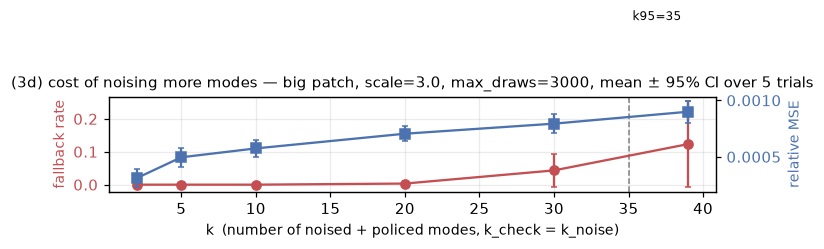

[read-off] both fallback and rel-MSE rise with k (more noised+policed modes). Truncating k would
           lower both, but that silences tail modes — the privacy leak full-rank noise prevents.
           The acceptance fix is k_check < k_noise (§3a), not reducing k_noise.


In [8]:
# (3d) k_noise effect on the big patch: fallback and fidelity vs number of noised+policed modes.
k_values = [2, 5, 10, 20, 30, 39]
n_trials = 5                                  # fresh big patches, for error bars
MAX_DRAWS_3D = FIXED_MAXDRAWS                  # rejection budget behind every fallback estimate here
records = {k: {"fallback": [], "rel_mse": []} for k in k_values}
k95_values = []
for trial in range(n_trials):
    y, D, S = big_patch_artifacts(trial_seed=trial)
    k95_values.append(effective_rank_95(me.patch_modes(D)[1]))
    for k in k_values:
        model = me.mech_mode_eigen(y, D, S, scale=FIXED_SCALE, k_noise=k, k_check=k, max_draws=MAX_DRAWS_3D)
        util = ph.utility_panel(y, model, BIG_SIZE, np.random.default_rng(trial), n_rel=60)
        records[k]["fallback"].append(model.fallback_rate)
        records[k]["rel_mse"].append(util["rel_mse"])

def mean_ci(values):
    v = np.array(values, float); m = v.mean()
    half = 1.96 * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0
    return m, half

fb_m, fb_e = zip(*[mean_ci(records[k]["fallback"]) for k in k_values])
mse_m, mse_e = zip(*[mean_ci(records[k]["rel_mse"]) for k in k_values])
k95_big = int(np.round(np.mean(k95_values)))

fig, ax_left = plt.subplots(figsize=(7.2, 4.4))
ax_left.errorbar(k_values, fb_m, yerr=fb_e, marker="o", color="#c44e52", capsize=2, label="fallback rate")
ax_left.set_xlabel("k  (number of noised + policed modes, k_check = k_noise)")
ax_left.set_ylabel("fallback rate", color="#c44e52"); ax_left.tick_params(axis="y", labelcolor="#c44e52")
ax_left.axvline(k95_big, ls="--", color="gray", lw=1); ax_left.text(k95_big, 0.5, f" k95={k95_big}", fontsize=8)
ax_right = ax_left.twinx(); ax_right.grid(False)
ax_right.errorbar(k_values, mse_m, yerr=mse_e, marker="s", color="#4c72b0", capsize=2, label="relative MSE")
ax_right.set_ylabel("relative MSE", color="#4c72b0"); ax_right.tick_params(axis="y", labelcolor="#4c72b0")
ax_left.set_title(f"(3d) cost of noising more modes — big patch, scale={FIXED_SCALE}, max_draws={MAX_DRAWS_3D}, "
                  f"mean ± 95% CI over {n_trials} trials")
fig.tight_layout(); plt.show()
print(f"[read-off] both fallback and rel-MSE rise with k (more noised+policed modes). Truncating k would\n"
      f"           lower both, but that silences tail modes — the privacy leak full-rank noise prevents.\n"
      f"           The acceptance fix is k_check < k_noise (§3a), not reducing k_noise.")

## §4 — Utility (patch level, no privacy)

How faithfully the released field preserves the signal, for three bar choices at matched noise power. **Relative
MSE alone is insufficient**: it is unbounded and heavy-tailed (so a few degenerate patches dominate it), and it
is blind to spatial structure. We report it alongside three complements — **neighbour-corr gap** (spatial
smoothness distortion), **Spearman** (rank/ordering preservation), and **bias_norm** (systematic shift of the
mean released field, which rejection sampling can introduce). All four come from one utility panel per draw.

The three mechanisms, swept on a shared `scale` knob (for the voxel mechanisms the equivalent knob is
`epsilon = 2/scale`, giving the **same total noise power** `scale²·trace(Cov(LOO))`, so the comparison isolates
the **bar**, not the amount): **mode-eigen** (this notebook), **voxel-L2** (L2-selected voxel bar), **voxel-max**
(per-voxel `max_i|D_ij|` bar). The three-way comparison runs at **small** patch sizes, because the two voxel
mechanisms form a `p × p` covariance and cannot run at the big patch (≈15 GB); a mode-eigen-only check at the
big patch follows.

In [9]:
# shared-scale mechanism factory (voxel mechanisms: epsilon = 2/scale  => same total power as mode-eigen)
def mechanisms_at_scale(scale_value):
    voxel_eps = 2.0 / scale_value
    voxel_max = ph.mech_supervisor_loo_corr(epsilon=voxel_eps, max_draws=256)   # per-voxel max bar
    return {
        "mode-eigen": (me.mech_mode_eigen, {"scale": scale_value, "max_draws": FIXED_MAXDRAWS}),
        "voxel-L2":   (l2s.l2_bar(voxel_max), {}),
        "voxel-max":  (voxel_max, {}),
    }

def bootstrap_median_ci(values, n_boot=2000, seed=0):
    '''Bootstrap 95% CI of the median, NaN-aware (degenerate trials dropped, counted separately).
    Returns (median, ci_lo, ci_hi, n_degenerate). The CI is the PRECISION of the typical value and
    narrows with more trials (unlike the IQR spread, which is a property of the patch population).'''
    v = np.asarray(values, float)
    finite = v[np.isfinite(v)]
    n_degenerate = int(v.size - finite.size)                 # trials where the metric was undefined (NaN)
    if finite.size == 0:
        return np.nan, np.nan, np.nan, n_degenerate
    rng = np.random.default_rng(seed)
    boot_medians = [np.median(finite[rng.integers(0, finite.size, finite.size)]) for _ in range(n_boot)]
    return (float(np.median(finite)), float(np.percentile(boot_medians, 2.5)),
            float(np.percentile(boot_medians, 97.5)), n_degenerate)

def utility_over_trials(patch_shape, pipeline, mechanism, cfg, n_rel=80, n_trials=8):
    '''Median of four utility metrics + fallback over n_trials fresh patches, with a bootstrap 95% CI
    (precision of the typical value) and the per-metric count of degenerate (NaN) trials.
    Returns {metric: (median, ci_lo, ci_hi)} and {metric+'_ndeg': n_degenerate}.'''
    collected = {k: [] for k in ("rel_mse", "neighbour_corr_gap", "spearman", "bias_norm", "fallback_rate")}
    for patch_seed in range(n_trials):                       # each trial is a fresh patch (varying location)
        y, D, S = small_patch_artifacts(patch_shape, pipeline=pipeline, patch_seed=patch_seed)
        model = mechanism(y, D, S, **cfg)
        util = ph.utility_panel(y, model, patch_shape, np.random.default_rng(100 + patch_seed), n_rel=n_rel)
        for k in ("rel_mse", "neighbour_corr_gap", "spearman", "bias_norm"):
            collected[k].append(util[k])
        collected["fallback_rate"].append(model.fallback_rate)
    out = {}
    for k, v in collected.items():
        med, lo, hi, n_deg = bootstrap_median_ci(v)
        out[k] = (med, lo, hi); out[k + "_ndeg"] = n_deg
    return out
print("utility helpers ready:", list(mechanisms_at_scale(FIXED_SCALE)))

utility helpers ready: ['mode-eigen', 'voxel-L2', 'voxel-max']


### §4a — Utility vs scale, by statistic and mechanism

**Plot.** Rows = the four metrics (rel-MSE, neighbour-corr gap, Spearman, bias_norm); columns = statistic
(mean/median/variance, title-coloured). Within each panel, one line per mechanism vs `scale` (log x), drawn as
the **median over trials with a bootstrap 95% CI band**. The band is the *precision of the typical value*
(so non-overlapping bands = a real difference between mechanisms), computed NaN-aware so a single degenerate
patch no longer blanks a cell — the number of degenerate trials is printed instead. rel-MSE and bias use a log
y-axis. **Read:** lower is better for rel-MSE / neighbour-corr gap / bias_norm; higher is better for Spearman.
Watch especially the **neighbour-corr gap** (the spatial axis rel-MSE is blind to). *Note on the median
statistic:* on some patches its clean field is spatially near-constant, which makes the rank-based Spearman and
neighbour-corr metrics undefined (NaN) for that trial — those counts are reported, and the degeneracy itself is
cross-checked with `cov_diagnostics` below.

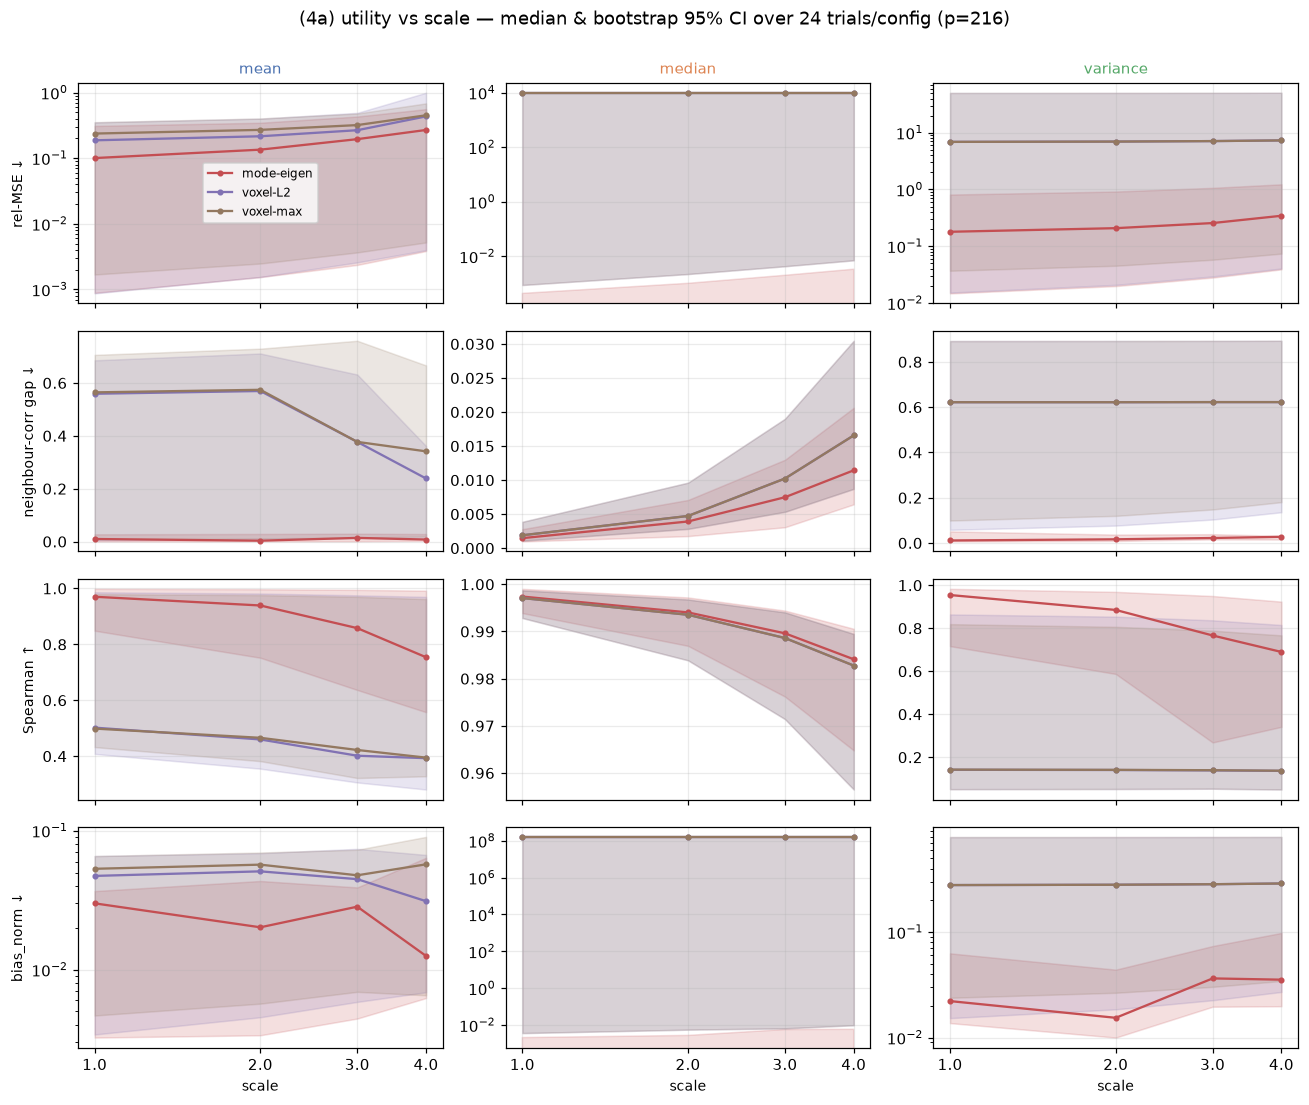

[degenerate trials] out of 288 trial-configs per statistic (undefined metric -> dropped):
   mean    : none
   median  : {'neighbour_corr_gap': 168, 'spearman': 168}
   variance: none
[cov_diagnostics] one patch per statistic (rank / flags):
   mean    : rank 39/216, flags: RANK_DEFICIENT (39/216)
   median  : rank 39/216, flags: RANK_DEFICIENT (39/216); ZERO_SENSITIVITY at dims [178, 179, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215]
   variance: rank 39/216, flags: RANK_DEFICIENT (39/216)


In [10]:
# (4a) four metrics (rows) x statistic (cols); median + bootstrap-95%-CI band; lines = mechanisms.
patch_shape = (6, 6, 6)
N_TRIALS_4A = 24                                     # fresh patches per (statistic, mechanism, scale)
metric_rows = [("rel_mse", "rel-MSE ↓", True), ("neighbour_corr_gap", "neighbour-corr gap ↓", False),
               ("spearman", "Spearman ↑", False), ("bias_norm", "bias_norm ↓", True)]
statistics = ["mean", "median", "variance"]
degenerate_counts = {stat: {key: 0 for key, _, _ in metric_rows} for stat in statistics}  # NaN trials tally
fig, axes = plt.subplots(len(metric_rows), len(statistics), figsize=(12, 10), sharex=True)
for col, stat in enumerate(statistics):
    for mech_name in MECH_COLOR:
        curves = {m[0]: ([], [], [], []) for m in metric_rows}   # scale, median, ci_lo, ci_hi
        for scale_value in SCALE_GRID:
            mech, cfg = mechanisms_at_scale(scale_value)[mech_name]
            pt = utility_over_trials(patch_shape, PIPELINES[stat], mech, cfg, n_trials=N_TRIALS_4A)
            for key, _, _ in metric_rows:
                med, lo, hi = pt[key]
                curves[key][0].append(scale_value); curves[key][1].append(med)
                curves[key][2].append(lo); curves[key][3].append(hi)
                degenerate_counts[stat][key] += pt[key + "_ndeg"]
        for row, (key, _, _) in enumerate(metric_rows):
            xs, med, lo, hi = map(np.array, curves[key])
            axes[row, col].plot(xs, med, "o-", ms=3, color=MECH_COLOR[mech_name], label=mech_name)
            axes[row, col].fill_between(xs, lo, hi, color=MECH_COLOR[mech_name], alpha=0.18)
    for row, (key, ylabel, logy) in enumerate(metric_rows):
        a = axes[row, col]
        a.set_xscale("log"); a.minorticks_off()
        a.set_xticks(SCALE_GRID); a.set_xticklabels([str(s) for s in SCALE_GRID])
        if logy:
            a.set_yscale("log")
        if col == 0:
            a.set_ylabel(ylabel)
        if row == 0:
            a.set_title(stat, color=STAT_COLOR[stat])
        if row == len(metric_rows) - 1:
            a.set_xlabel("scale")
axes[0, 0].legend(fontsize=8, loc="best")
fig.suptitle(f"(4a) utility vs scale — median & bootstrap 95% CI over {N_TRIALS_4A} trials/config (p=216)", y=1.0)
fig.tight_layout(); plt.show()

# degenerate (NaN) trials per statistic — explains any gaps in the rank-based metric rows
n_configs = len(MECH_COLOR) * len(SCALE_GRID) * N_TRIALS_4A
print(f"[degenerate trials] out of {n_configs} trial-configs per statistic (undefined metric -> dropped):")
for stat in statistics:
    nz = {k: c for k, c in degenerate_counts[stat].items() if c}
    print(f"   {stat:8s}: {nz if nz else 'none'}")
# structural cross-check with cov_diagnostics (rank / degeneracy flags)
print("[cov_diagnostics] one patch per statistic (rank / flags):")
subjects = ph.ArrayBlockSource(VOLUMES, BRAIN_MASK, block_shape=patch_shape, N=N_SUBJECTS,
                               seed=SEED).sample(N_SUBJECTS, np.random.default_rng(0)).reshape(N_SUBJECTS, -1)
for stat in statistics:
    rep = cd.covariance_report(subjects, PIPELINES[stat], name=stat)
    print(f"   {stat:8s}: rank {rep['rank']}/{rep['p']}, flags: {'; '.join(rep['flags']) or 'none'}")

### §4b — Noise structure, per statistic, at a larger patch

**Question.** How does each mechanism's noise *look*, and does that differ by statistic? The released field is
clean + noise, and at useful scales the noise is far below the anatomy, so released fields look identical — we
show the **noise** (`released − clean`) directly. **Layout.** One **row per statistic** (mean/median/variance).
**Column 1** = that statistic's **clean output field** with its *own* colour scale + colourbar (a variance field
and a mean field span very different ranges). **Columns 2–4** = the noise from mode-eigen / voxel-L2 / voxel-max
on a **shared symmetric** diverging scale *within each row* (so the three mechanisms are directly comparable for
that statistic, each row scaled to its own noise magnitude). Same patch location and same mid-axial slice across
all rows; patch = **16³ (p=4096)**, scale = 2. **Read.** mode-eigen noise should be spatially **smooth**
(eigenmode-shaped); the voxel bars give **grainier**, less coherent noise — the visual counterpart of the
neighbour-corr gap in §4a. (16³ is the largest size at which the voxel mechanisms' `p×p` covariance still fits;
they OOM at the big patch.)

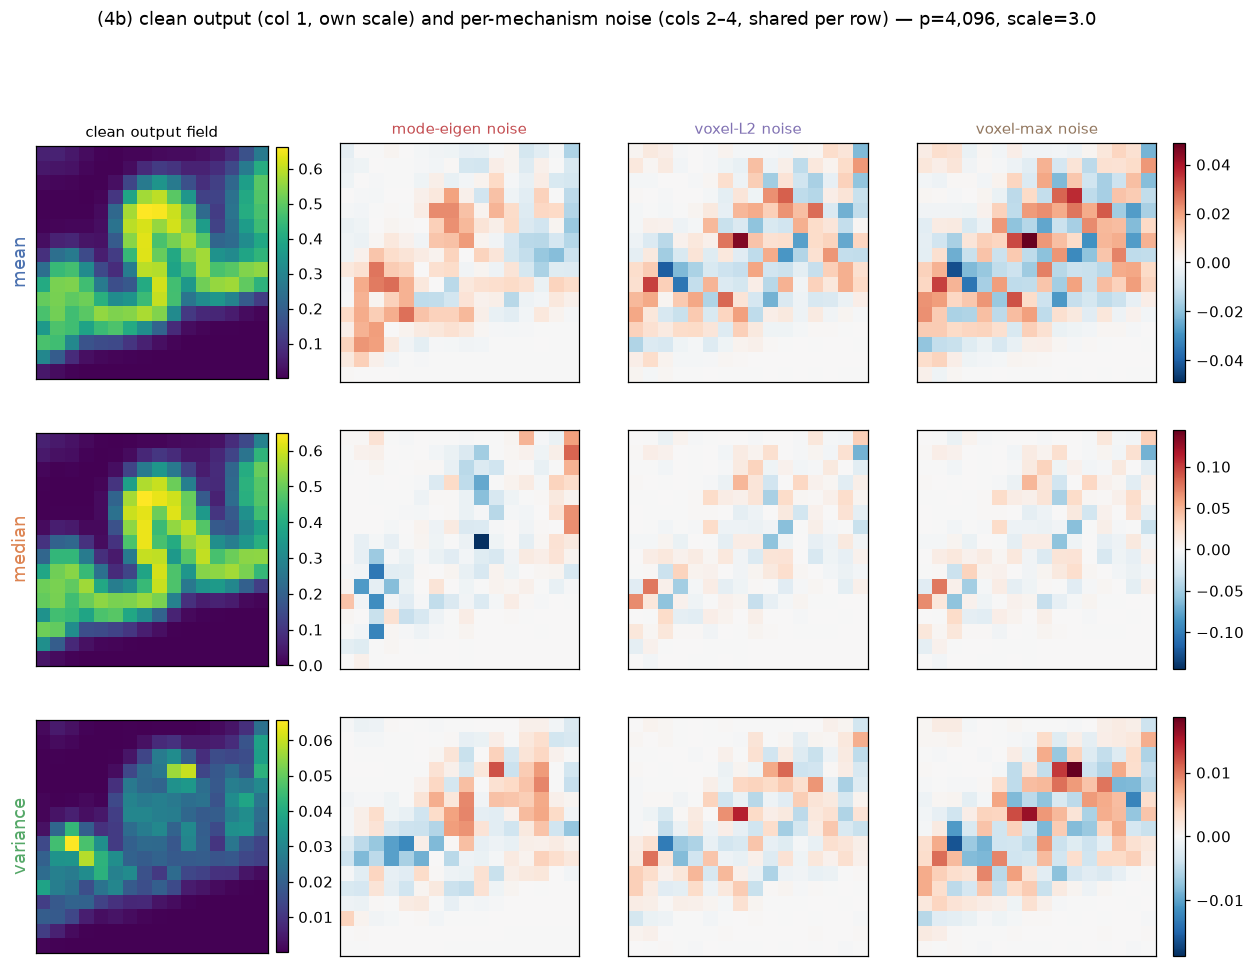

[read-off] within each row the three noise panels share a scale, so compare spatial smoothness:
           mode-eigen noise follows the eigenmodes (coherent); the voxel bars are grainier — the
           visual counterpart of the neighbour-corr gap in §4a.


In [11]:
# (4b) per-statistic noise structure at 16^3. Rows = statistic; col 1 = clean output (own scale);
#      cols 2-4 = each mechanism's noise (released-clean), shared symmetric scale PER ROW.
field_shape = (16, 16, 16)
field_subjects = ph.ArrayBlockSource(VOLUMES, BRAIN_MASK, block_shape=field_shape, N=N_SUBJECTS,
                                     seed=SEED).sample(N_SUBJECTS, np.random.default_rng(0)).reshape(N_SUBJECTS, -1)
mid = field_shape[2] // 2
mech_names = list(MECH_COLOR)

def mechanisms_4b(scale_value):
    # voxel mechs form a 4096x4096 covariance; a tiny max_draws keeps one sample cheap (they fall back anyway)
    voxel_max = ph.mech_supervisor_loo_corr(epsilon=2.0 / scale_value, max_draws=16)
    return {"mode-eigen": (me.mech_mode_eigen, {"scale": scale_value, "max_draws": FIXED_MAXDRAWS}),
            "voxel-L2":   (l2s.l2_bar(voxel_max), {}),
            "voxel-max":  (voxel_max, {})}

fig, axes = plt.subplots(len(statistics), 1 + len(mech_names),
                         figsize=(3.4 * (1 + len(mech_names)), 3.2 * len(statistics)))
for row, stat in enumerate(statistics):
    y, D, S = ph.loo_artifacts(field_subjects, PIPELINES[stat])
    clean = y.reshape(field_shape)
    im_clean = axes[row, 0].imshow(clean[:, :, mid], cmap="viridis")           # own colour scale per statistic
    axes[row, 0].set_ylabel(stat, color=STAT_COLOR[stat], fontsize=12)
    if row == 0: axes[row, 0].set_title("clean output field")
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    fig.colorbar(im_clean, ax=axes[row, 0], fraction=0.046, pad=0.03)
    noises = {name: mech(y, D, S, **cfg).sample(np.random.default_rng(7)).reshape(field_shape)
              for name, (mech, cfg) in mechanisms_4b(FIXED_SCALE).items()}
    row_vmax = max(np.abs(z[:, :, mid]).max() for z in noises.values())        # shared symmetric scale per row
    for col, name in enumerate(mech_names, start=1):
        im_noise = axes[row, col].imshow(noises[name][:, :, mid], cmap="RdBu_r", vmin=-row_vmax, vmax=row_vmax)
        if row == 0: axes[row, col].set_title(f"{name} noise", color=MECH_COLOR[name])
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
    fig.colorbar(im_noise, ax=axes[row, 1:], fraction=0.025, pad=0.02)         # one noise colourbar per row
fig.suptitle(f"(4b) clean output (col 1, own scale) and per-mechanism noise (cols 2–4, shared per row) — "
             f"p={np.prod(field_shape):,}, scale={FIXED_SCALE}", y=1.005)
plt.show()
print("[read-off] within each row the three noise panels share a scale, so compare spatial smoothness:\n"
      "           mode-eigen noise follows the eigenmodes (coherent); the voxel bars are grainier — the\n"
      "           visual counterpart of the neighbour-corr gap in §4a.")

## §5 — Do noise subspaces transport across the brain?

**Why this matters.** A cheap release would estimate a covariance once and *reuse* it across locations. That is
only valid if different patches share the same top-mode subspace. We test it directly.

**Subspace overlap — definition.** For two patches A, B, take their top-`k` eigenmode matrices `V_A, V_B`
(each `p × k`, orthonormal columns). The overlap is
`‖V_Aᵀ V_B‖_F² / k = (1/k) Σ_{i=1}^{k} cos²θ_i`,
where `θ_i` are the **principal angles** between the two subspaces. It lies in **[0, 1]**: **1** = identical
subspace, **0** = orthogonal (no shared directions). Equivalently it is the average squared cosine of the
principal angles.

**What counts as "a lot" of overlap — reference values.** The metric is only interpretable against its scale,
which is set by `k` and the ambient dimension `p`:
- **1.0** — identical subspaces (perfect transport; a borrowed covariance would lose nothing).
- **≈ `k/p`** — the **random baseline**: two *unrelated* `k`-dim subspaces of ℝᵖ overlap by about `k/p` because
  each basis direction of A keeps ~`k/p` of its length in a random `k`-dim B. At `p = 216` that is 2/216 ≈ 0.009
  (k=2), 0.023 (k=5), 0.046 (k=10) — so an overlap of 0.3 is unremarkable at `p=20` but strong at `p=216`.
- **In between** — partial sharing: ~0.5 means the two patches share about half of each other's top-`k` variance
  directions. There is no universal "good" value; what matters is the **ratio to `k/p`** and the **trend vs
  distance**.

**The plot.** x = Euclidean distance between patch centres (voxels); y = overlap; one line per `k` (top-2/5/10),
binned over all patch pairs with 95% CIs.

**The random-subspace null (the dotted lines) — four questions.**
1. *What it represents:* the overlap you would see with **no shared structure** — pure chance.
2. *How it is built:* draw two Haar-random orthonormal `k`-frames in ℝᵖ (QR of Gaussian matrices), compute their
   overlap, average over many draws; its value is ≈ `k/p`, one line per `k`.
3. *What comparing to it answers:* "is the measured overlap more than coincidence?"
4. *What to infer:* overlap **near** the null ⇒ patches share no more than random directions, so reusing one
   covariance elsewhere is **unjustified**; **well above** it ⇒ real shared structure (reuse *might* transport),
   but overlap still `< 1` means the borrowed subspace **misses part of the local signal** — the same failure
   family as truncation.

**Read (any dataset):** the trend *vs distance* says whether shared structure is local (decays toward the null),
global (flat and high), or anatomically organised (e.g. a rise at large distance ⇒ bilaterally symmetric
structure). Overlap near the null at all distances would reject covariance reuse outright.

collected 45 in-brain patches of size (6, 6, 6)


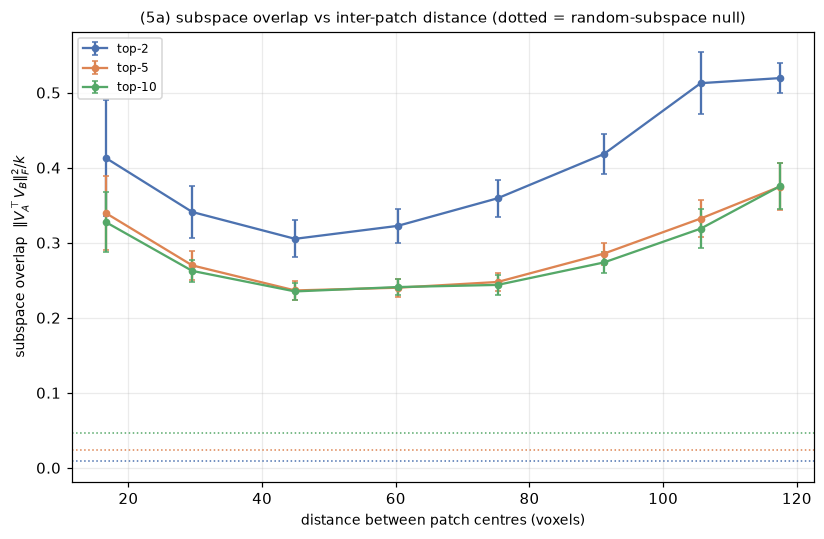

[read-off] top-5 overlap: 0.34 (near) vs 0.37 (far), random-subspace null 0.024.
           Overlap sits well above the null at all distances and rises at long range (structure may be bilaterally organised).
           => borrowing a covariance from another location mis-noises the local signal outside the
           borrowed subspace; honest per-patch covariances (global-LOO-once) remain the release path.


In [13]:
# (5a) subspace overlap vs inter-patch distance, with the random-subspace null band.
from scipy.linalg import subspace_angles
overlap_shape = (6, 6, 6); top_k_values = [2, 5, 10]; n_patches = 45
px, py, pz = overlap_shape; X, Y, Z = BRAIN_MASK.shape
rng_patch = np.random.default_rng(0)
patch_modes_list, patch_centres = [], []
tries = 0
while len(patch_modes_list) < n_patches and tries < 6000:
    tries += 1
    x0, y0, z0 = (rng_patch.integers(0, X - px + 1), rng_patch.integers(0, Y - py + 1),
                  rng_patch.integers(0, Z - pz + 1))
    if BRAIN_MASK[x0:x0+px, y0:y0+py, z0:z0+pz].all():
        _, D, _ = ph.loo_artifacts(VOLUMES[:, x0:x0+px, y0:y0+py, z0:z0+pz], ph.pipeline_mean)
        patch_modes_list.append(me.patch_modes(D)[0])
        patch_centres.append((x0 + px/2, y0 + py/2, z0 + pz/2))
patch_centres = np.array(patch_centres)
p_dim = patch_modes_list[0].shape[0]
print(f"collected {len(patch_modes_list)} in-brain patches of size {overlap_shape}")

def subspace_overlap(Va, Vb, k):
    return float(np.sum(np.cos(subspace_angles(Va[:, :k], Vb[:, :k]))**2) / k)

def random_null_overlap(p, k, reps=120):
    vals = [subspace_overlap(np.linalg.qr(rng_patch.standard_normal((p, k)))[0],
                             np.linalg.qr(rng_patch.standard_normal((p, k)))[0], k) for _ in range(reps)]
    return float(np.mean(vals))

fig, ax = plt.subplots(figsize=(7.6, 5))
short_long = {}
for k, color in zip(top_k_values, ["#4c72b0", "#dd8452", "#55a868"]):
    dists, overlaps = [], []
    for i in range(len(patch_modes_list)):
        for j in range(i + 1, len(patch_modes_list)):
            dists.append(np.linalg.norm(patch_centres[i] - patch_centres[j]))
            overlaps.append(subspace_overlap(patch_modes_list[i], patch_modes_list[j], k))
    dists, overlaps = np.array(dists), np.array(overlaps)
    bins = np.linspace(dists.min(), dists.max(), 9); which = np.digitize(dists, bins)
    bx, by, be = [], [], []
    for b in range(1, len(bins)):
        sel = which == b
        if sel.sum() >= 5:
            bx.append(dists[sel].mean()); by.append(overlaps[sel].mean())
            be.append(1.96 * overlaps[sel].std(ddof=1) / np.sqrt(sel.sum()))
    ax.errorbar(bx, by, yerr=be, marker="o", ms=4, color=color, capsize=2, label=f"top-{k}")
    null = random_null_overlap(p_dim, k)
    ax.axhline(null, ls=":", color=color, lw=1)
    short_long[k] = (by[0], by[-1], null)
ax.set(xlabel="distance between patch centres (voxels)",
       ylabel=r"subspace overlap  $\|V_A^\top V_B\|_F^2 / k$",
       title="(5a) subspace overlap vs inter-patch distance (dotted = random-subspace null)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

near5, far5, null5 = short_long[5]
trend = ("rises at long range (structure may be bilaterally organised)" if far5 > near5 + 0.03
         else "decays with distance (structure is local)" if far5 < near5 - 0.03
         else "is roughly flat with distance (structure is broadly shared)")
print(f"[read-off] top-5 overlap: {near5:.2f} (near) vs {far5:.2f} (far), random-subspace null {null5:.3f}.\n"
      f"           Overlap sits well above the null at all distances and {trend}.\n"
      f"           => borrowing a covariance from another location mis-noises the local signal outside the\n"
      f"           borrowed subspace; honest per-patch covariances (global-LOO-once) remain the release path.")

## §6 — Compute: economy SVD vs dense `p × p`

**Question.** What does building the noise cost, and why does the dense approach fail at OASIS scale? The
mechanism never forms `Cov(LOO)` as `p × p`; it uses the economy SVD of the `N × p` perturbations
(`r = min(p, N−1)` modes) plus one `p`-vector assembly. The dense alternative costs `O(p²)` memory and `O(p³)`
time. **Plots.** Left: build time vs `p` (economy SVD vs dense eigendecomposition, measured where it fits, with
the `∝p³` projection and the crossover). Right: memory vs `p`, with the dense `p×p` line extended **through the
OASIS sizes** so its crossing of a RAM budget is visible. **Read:** the economy path stays cheap into the tens
of thousands of voxels; the dense path crosses any practical RAM budget well before the OASIS patch size.

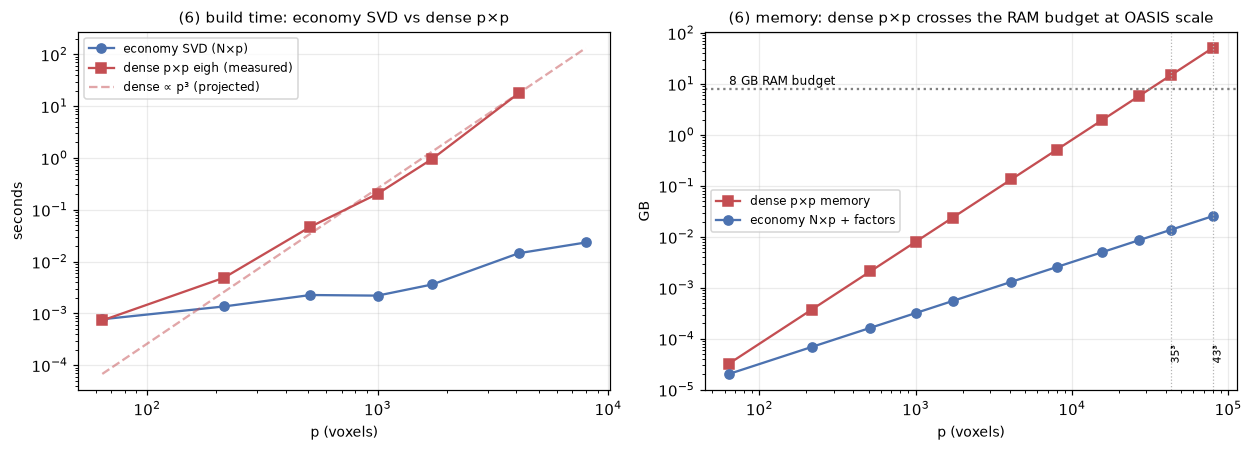

[read-off] the dense p×p matrix alone crosses the 8 GB budget at p≈31,623 voxels (~32³) — below the OASIS patch size — and eigendecomposition needs
           several more working copies, so the dense path OOMs well before 35³. The economy path
           needs only ~14 MB at 35³.


In [14]:
# (6) economy-SVD vs dense p×p: time (left) and memory extended through the OASIS sizes (right).
def economy_svd_seconds(p, reps=5):
    A = np.random.default_rng(0).standard_normal((N_SUBJECTS, p))
    times = []
    for _ in range(reps):
        t0 = time.perf_counter(); svd(A - A.mean(0), full_matrices=False); times.append(time.perf_counter()-t0)
    return np.median(times)

def dense_eigh_seconds(p):
    if p**2 * 8 > 3e8:                 # don't allocate > ~300 MB; project instead
        return None
    M = np.random.default_rng(0).standard_normal((p, p)); M = M @ M.T
    t0 = time.perf_counter(); np.linalg.eigh(M); return time.perf_counter() - t0

sampled_sides = [4, 6, 8, 10, 12, 16, 20]
sampled_p = np.array([s**3 for s in sampled_sides])
econ_times = np.array([economy_svd_seconds(p) for p in sampled_p])
dense_times = [dense_eigh_seconds(p) for p in sampled_p]
RAM_BUDGET_GB = 8.0                                     # comfortably-available per-process RAM (eigh needs
                                                        # several working copies on top of the p×p matrix)
mem_sides = sampled_sides + [25, 30, 35, 43]            # extend THROUGH the OASIS sizes (35^3 etc.)
mem_p = np.array([s**3 for s in mem_sides])
dense_mem_gb = mem_p**2 * 8 / 1e9
econ_mem_gb = mem_p * N_SUBJECTS * 8 / 1e9

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].loglog(sampled_p, econ_times, "o-", color="#4c72b0", label="economy SVD (N×p)")
measured = [(p, t) for p, t in zip(sampled_p, dense_times) if t is not None]
mp, mt = np.array([p for p, _ in measured]), np.array([t for _, t in measured])
axes[0].loglog(mp, mt, "s-", color="#c44e52", label="dense p×p eigh (measured)")
axes[0].loglog(sampled_p, (mt[-1]/mp[-1]**3) * sampled_p**3.0, "--", color="#c44e52", alpha=0.5,
               label="dense ∝ p³ (projected)")
axes[0].set(xlabel="p (voxels)", ylabel="seconds", title="(6) build time: economy SVD vs dense p×p")
axes[0].legend(fontsize=8)
axes[1].loglog(mem_p, dense_mem_gb, "s-", color="#c44e52", label="dense p×p memory")
axes[1].loglog(mem_p, econ_mem_gb, "o-", color="#4c72b0", label="economy N×p + factors")
axes[1].axhline(RAM_BUDGET_GB, ls=":", color="gray"); axes[1].text(mem_p[0], RAM_BUDGET_GB*1.2,
              f"{RAM_BUDGET_GB:.0f} GB RAM budget", fontsize=8)
for s in (35, 43):
    axes[1].axvline(s**3, ls=":", color="0.7", lw=0.8); axes[1].text(s**3, dense_mem_gb.min(), f"{s}³",
              fontsize=7, rotation=90, va="bottom")
axes[1].set(xlabel="p (voxels)", ylabel="GB", title="(6) memory: dense p×p crosses the RAM budget at OASIS scale")
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

crossing_p = (RAM_BUDGET_GB * 1e9 / 8) ** 0.5
print(f"[read-off] the dense p×p matrix alone crosses the {RAM_BUDGET_GB:.0f} GB budget at p≈{crossing_p:,.0f} "
      f"voxels (~{crossing_p**(1/3):.0f}³) — below the OASIS patch size — and eigendecomposition needs\n"
      f"           several more working copies, so the dense path OOMs well before 35³. The economy path\n"
      f"           needs only ~{(35**3)*N_SUBJECTS*8/1e6:.0f} MB at 35³.")

In [15]:
# (6) the formerly-OOM OASIS sizes build via economy SVD in milliseconds; dense would need ~15 GB.
for side in [BIG_SIZE, (43, 30, 31)]:
    p = int(np.prod(side))
    A = np.random.default_rng(0).standard_normal((N_SUBJECTS, p))      # N×p only; never p×p
    t0 = time.perf_counter(); U, s, Vt = svd(A - A.mean(0), full_matrices=False)
    dt = time.perf_counter() - t0
    print(f"size {side}: p={p:,}  economy SVD {dt*1000:.0f} ms, extra memory ≈ {p*N_SUBJECTS*8/1e6:.0f} MB "
          f"(modes {Vt.shape[0]}×{Vt.shape[1]:,}); dense p×p would need {p*p*8/1e9:.1f} GB.")

size (35, 35, 35): p=42,875  economy SVD 188 ms, extra memory ≈ 14 MB (modes 40×42,875); dense p×p would need 14.7 GB.
size (43, 30, 31): p=39,990  economy SVD 170 ms, extra memory ≈ 13 MB (modes 40×39,990); dense p×p would need 12.8 GB.


## §7 — Conclusions & hand-off to NB7

- **Correctness** (§2): natural draws reproduce `scale²·Cov(LOO)` to entrywise correlation ≈ 1, and released
  noise is a genuine eigenmode combination. The construction is exact.
- **Efficiency** (§3): fallback is governed by rejection depth `k_check` and `scale` (§3a); a draw budget buys
  lower fallback at linear time (§3b/c); and noising more modes (`k_noise↑`) costs both acceptance and fidelity
  (§3d) — so full-rank noise is kept for privacy and `k_check` is the acceptance lever, not truncation.
- **Utility** (§4): judged on four complementary metrics, mode-eigen preserves spatial structure
  (neighbour-corr gap) best and avoids the degeneracy-driven rel-MSE blow-ups the voxel bars show on nonlinear
  statistics; it is also the only mechanism that runs at the OASIS patch size.
- **Subspace transport** (§5): overlap sits above the random-subspace null at all distances but is far from 1,
  so reusing a covariance across locations mis-noises the local signal — honest per-patch covariances remain the
  release path.
- **Compute** (§6): the economy SVD runs the OASIS-scale patches in milliseconds where the dense `p×p` path
  crosses a RAM budget well before that size.

**Carries into NB7:** the mechanism (`mode_eigen_mech.mech_mode_eigen`), the `k_check × scale` fallback map
(§3a) and the utility curves (§4a) as the design information, the per-patch-covariance decision, and the
**operating point** chosen here — `FIXED_SCALE`, `FIXED_KCHECK`, `FIXED_MAXDRAWS` at the top of §0, a sweet spot
giving a sensible fallback rate at acceptable utility. Because there is no patch-level utility/fallback
trade-off (§4 note), its final validation is against the privacy floor **in NB7**, not here. **Deferred to
NB7:** whole-release assembly/overlap; the privacy tests (reconstruction — aggregate and individual; k-sigma
outlier identification); the privacy payoff of `k_noise`; **the `max_draws`↔total-compute/throughput scaling
study** (across the many-patch workload); and zarr for the big sweep outputs.